<a href="https://colab.research.google.com/github/alkadevirajbanshi-ai/Intelligence-System/blob/main/Reinforcement_Learning.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [14]:
#Modified from:
#https://amunategui.github.io/reinforcement-learning/index.html
#http://firsttimeprogrammer.blogspot.com/2016/09/getting-ai-smarter-with-q-learning.html
#http://mnemstudio.org/path-finding-q-learning-tutorial.htm
import numpy as np
import pylab as plt

# map cell to cell, add circular cell to goal point
#points_list = [(0,1), (1,5), (5,6), (5,4), (1,2), (2,3), (2,7)]

In [15]:
# Each pair (a, b) is a connection between two states (nodes).
# These connections form the map the agent can move through.
points_list = [(0,1),(1,2),(1,3),(2,4),(3,5),(3,6)]

In [16]:
# State 6 is the destination the agent must reach.
goal = 6
#goal = 7

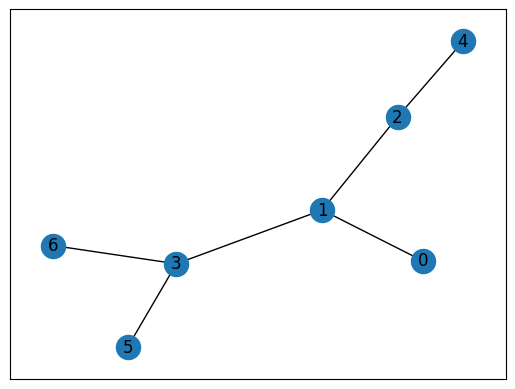

In [17]:
# NetworkX creates and displays the map as a graph.
# Nodes are states; lines are paths between them.

import networkx as nx
G=nx.Graph()
G.add_edges_from(points_list)
pos = nx.spring_layout(G)
nx.draw_networkx_nodes(G,pos)
nx.draw_networkx_edges(G,pos)
nx.draw_networkx_labels(G,pos)
plt.show()

In [18]:
# There are 7 states, numbered 0 through 6.
# Each reward/Q matrix needs one row and column per state.
# how many points in graph? x points
MATRIX_SIZE = 7

In [19]:
# R is the reward matrix: R[from_state, to_state].
# Start with -1 everywhere to mark moves that are not allowed.

# create matrix x*y or Value Matrix
R = np.matrix(np.ones(shape=(MATRIX_SIZE, MATRIX_SIZE)))
R *= -1

In [20]:
# Give valid paths a reward of 0 and paths entering the goal 100.
# Since the graph is undirected, fill both directions of each path.
# Also allow the agent to stay at the goal with reward 100.

# assign zeros to paths and 100 to goal-reaching point
for point in points_list:
    print(point)
    if point[1] == goal:
        R[point] = 100
    else:
        R[point] = 0

    if point[0] == goal:
        R[point[::-1]] = 100
    else:
        # reverse of point
        R[point[::-1]]= 0

# add goal point round trip
R[goal,goal]= 100

(0, 1)
(1, 2)
(1, 3)
(2, 4)
(3, 5)
(3, 6)


In [21]:
# Display R to check which moves are valid and rewarding.

# display value matrix
R

matrix([[ -1.,   0.,  -1.,  -1.,  -1.,  -1.,  -1.],
        [  0.,  -1.,   0.,   0.,  -1.,  -1.,  -1.],
        [ -1.,   0.,  -1.,  -1.,   0.,  -1.,  -1.],
        [ -1.,   0.,  -1.,  -1.,  -1.,   0., 100.],
        [ -1.,  -1.,   0.,  -1.,  -1.,  -1.,  -1.],
        [ -1.,  -1.,  -1.,   0.,  -1.,  -1.,  -1.],
        [ -1.,  -1.,  -1.,   0.,  -1.,  -1., 100.]])

In [22]:
# Q stores the learned value of moving from one state to another.
# Start at zero because the agent has not learned yet.
# gamma (0.8) discounts future rewards: larger values favor future gains.
# initial_state is the example state used for the first update.
# available_actions(state) finds valid next states (R >= 0).
# sample_next_action(...) randomly picks one to explore.

# Create Q Matrix
Q = np.matrix(np.zeros([MATRIX_SIZE,MATRIX_SIZE]))

#Creates a Q-matrix filled with zeros. This matrix will be updated during learning, with rows representing states and columns representing actions.

# learning parameter/discount factor
gamma = 0.8

initial_state = 1
#This sets the starting point for the agent's learning to state 1.

#Define available_actions Function:
def available_actions(state):
    current_state_row = R[state,]
    av_act = np.where(current_state_row >= 0)[1]
    return av_act

    #Given a state, the above function identifies all possible actions by checking the corresponding row in the reward matrix R.
    #Actions with non-negative values in R are considered "available."

available_act = available_actions(initial_state)

#define a function to Randomly selects an action from the list of available actions, helping the agent explore the environment.

def sample_next_action(available_actions_range):
    next_action = int(np.random.choice(available_act,1))
    return next_action

action = sample_next_action(available_act)

/tmp/ipykernel_3207/2401770556.py:33: DeprecationWarning: Conversion of an array with ndim > 0 to a scalar is deprecated, and will error in future. Ensure you extract a single element from your array before performing this operation. (Deprecated NumPy 1.25.)
  next_action = int(np.random.choice(available_act,1))


In [23]:
# Update Q using: reward + gamma * best future Q value.
# Find the best action from the next state; break ties randomly.
# Save the new Q value for the selected state/action pair.
# Return a normalized sum of Q values as a training score.
# The final call demonstrates one learning update.

def update(current_state, action, gamma):

  max_index = np.where(Q[action,] == np.max(Q[action,]))[1]

  if max_index.shape[0] > 1:
      max_index = int(np.random.choice(max_index, size = 1))
  else:
      max_index = int(max_index)
  max_value = Q[action, max_index]

  Q[current_state, action] = R[current_state, action] + gamma * max_value
  print('max_value', R[current_state, action] + gamma * max_value)

  if (np.max(Q) > 0):
    return(np.sum(Q/np.max(Q)*100))
  else:
    return (0)

update(initial_state, action, gamma)

max_value 0.0


/tmp/ipykernel_3207/2038434189.py:12: DeprecationWarning: Conversion of an array with ndim > 0 to a scalar is deprecated, and will error in future. Ensure you extract a single element from your array before performing this operation. (Deprecated NumPy 1.25.)
  max_index = int(np.random.choice(max_index, size = 1))


0

In [24]:
# Train for 700 updates, starting from a random state each time.
# Choose a valid action, update Q, and record its score.
# Finally print Q scaled relative to its largest value (0–100).

# Training
scores = []
for i in range(700):
    current_state = np.random.randint(0, int(Q.shape[0]))
    available_act = available_actions(current_state)
    action = sample_next_action(available_act)
    score = update(current_state,action,gamma)
    scores.append(score)
    print ('Score:', str(score))

print("Trained Q matrix:")
print(Q/np.max(Q)*100)

max_value 0.0
Score: 0
max_value 0.0
Score: 0
max_value 0.0
Score: 0
max_value 0.0
Score: 0
max_value 0.0
Score: 0
max_value 0.0
Score: 0
max_value 0.0
Score: 0
max_value 0.0
Score: 0
max_value 0.0
Score: 0
max_value 0.0
Score: 0
max_value 0.0
Score: 0
max_value 0.0
Score: 0
max_value 0.0
Score: 0
max_value 0.0
Score: 0
max_value 0.0
Score: 0
max_value 0.0
Score: 0
max_value 0.0
Score: 0
max_value 100.0
Score: 100.0
max_value 100.0
Score: 100.0
max_value 80.0
Score: 180.0
max_value 80.0
Score: 260.0
max_value 164.0
Score: 197.5609756097561
max_value 0.0
Score: 197.5609756097561
max_value 0.0
Score: 197.5609756097561
max_value 0.0
Score: 197.5609756097561
max_value 64.0
Score: 236.58536585365854
max_value 64.0
Score: 236.58536585365854
max_value 131.20000000000002
Score: 267.80487804878055
max_value 0.0
Score: 267.80487804878055
max_value 104.96000000000002
Score: 292.7804878048781
max_value 0.0
Score: 292.7804878048781
max_value 0.0
Score: 292.7804878048781
max_value 131.20000000000002

/tmp/ipykernel_3207/2401770556.py:33: DeprecationWarning: Conversion of an array with ndim > 0 to a scalar is deprecated, and will error in future. Ensure you extract a single element from your array before performing this operation. (Deprecated NumPy 1.25.)
  next_action = int(np.random.choice(available_act,1))
/tmp/ipykernel_3207/2038434189.py:12: DeprecationWarning: Conversion of an array with ndim > 0 to a scalar is deprecated, and will error in future. Ensure you extract a single element from your array before performing this operation. (Deprecated NumPy 1.25.)
  max_index = int(np.random.choice(max_index, size = 1))
/tmp/ipykernel_3207/2038434189.py:14: DeprecationWarning: Conversion of an array with ndim > 0 to a scalar is deprecated, and will error in future. Ensure you extract a single element from your array before performing this operation. (Deprecated NumPy 1.25.)
  max_index = int(max_index)


Most efficient path:
[0, 1, 3, 6]


/tmp/ipykernel_3207/2383824046.py:16: DeprecationWarning: Conversion of an array with ndim > 0 to a scalar is deprecated, and will error in future. Ensure you extract a single element from your array before performing this operation. (Deprecated NumPy 1.25.)
  next_step_index = int(next_step_index)


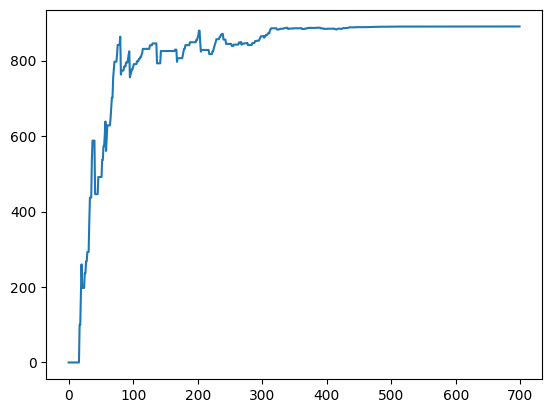

In [25]:
# Test the learned policy by starting at state 0.
# Repeatedly choose the next state with the highest Q value.
# Stop at state 6, print the path, and plot training scores.

# Testing
current_state = 0
steps = [current_state]

while current_state != 6:

    next_step_index = np.where(Q[current_state,] == np.max(Q[current_state,]))[1]

    if next_step_index.shape[0] > 1:
        next_step_index = int(np.random.choice(next_step_index, size = 1))
    else:
        next_step_index = int(next_step_index)

    steps.append(next_step_index)
    current_state = next_step_index

print("Most efficient path:")
print(steps)

plt.plot(scores)
plt.show()